In [15]:
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from beta_evidence_field import (OccupancyField, OccupancyObservation, OccupancyPrior)
from tools.plotting      import configure_plots, plot_observation_2d, plot_field_2d

In [16]:
field = OccupancyField(surface_covariance = 0.15**2*np.eye(2),
                       free_covariance    = 0.15**2*np.eye(2),
                       temporal_variance  = 10.0**2,
                       prior              = OccupancyPrior(1, 1))

observation = OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                   direction = np.array([1.0, 1.0]),
                                   range     = 3.0,
                                   returned  = True,
                                   time      = 0.0)

obs = field.add([observation])

In [17]:
x = np.linspace(-0.5, 3.0, 80)
y = np.linspace(-0.5, 3.0, 80)

X, Y = np.meshgrid(x, y, indexing = "ij")

points = np.column_stack((X.ravel(),
                          Y.ravel()))

surface = field.surface_kernel.evaluate(points = points, 
                                        centre = observation.endpoint).reshape(X.shape)

free    = field.free_kernel.convolve_line(points = points, 
                                          start  = observation.origin, 
                                          end    = observation.endpoint).reshape(X.shape)

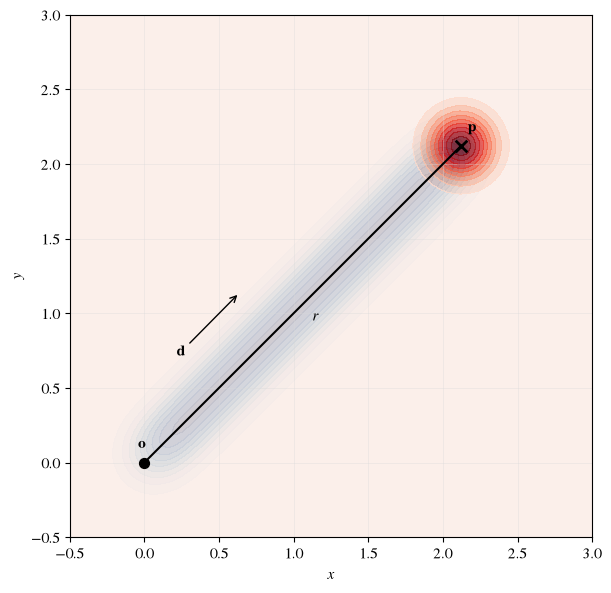

In [18]:
configure_plots()
plot = plot_observation_2d(X           = X,
                           Y           = Y,
                           surface     = surface,
                           free        = free,
                           observation = observation)

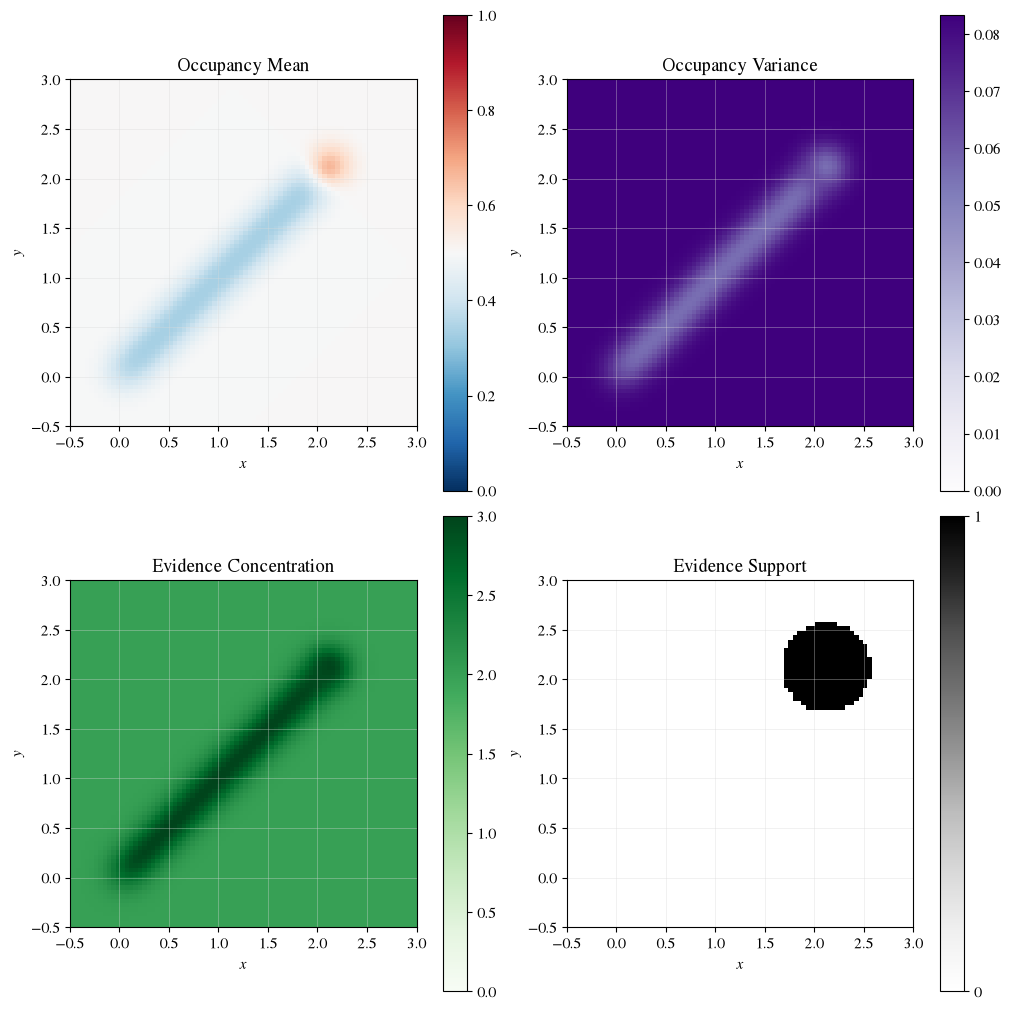

In [19]:
query   = field.query(points = points,
                      time   = 0.0)

plot    = plot_field_2d(X     = X,
                        Y     = Y,
                        query = query)

Generating observations: 100%|██████████| 50/50 [00:00<00:00, 40603.14it/s]


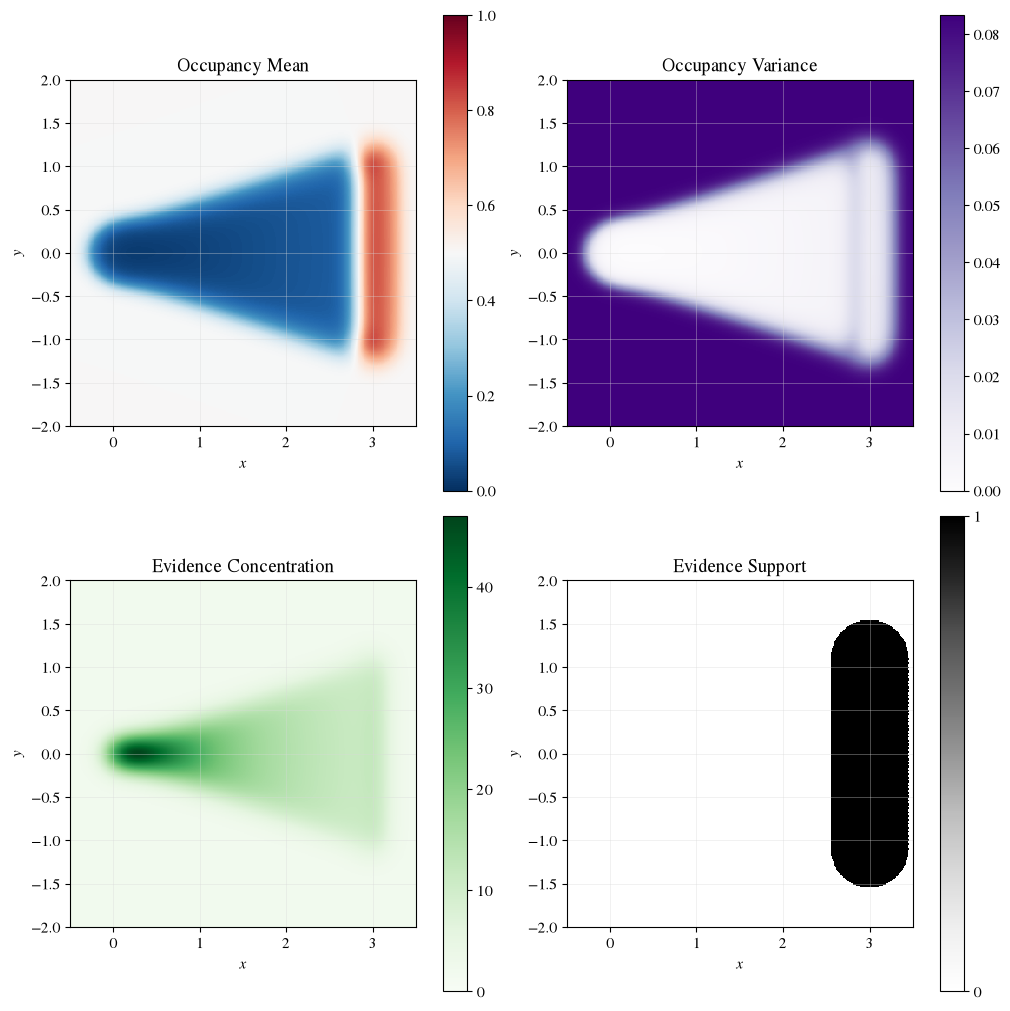

In [20]:
angles = np.linspace(-0.35, 0.35, 50)

observations = []

for angle in tqdm(angles, desc = "Generating observations"):
    direction = np.array([np.cos(angle), np.sin(angle)])
    observations.append(OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                             direction = direction,
                                             range     = 3.0/direction[0],
                                             returned  = True,
                                             time      = 0.0))


field.clear()
obs = field.add(observations)

x = np.linspace(-0.5, 3.5, 400)
y = np.linspace(-2, 2, 300)

X, Y = np.meshgrid(x, y)

points = np.column_stack((X.ravel(), Y.ravel()))

query   = field.query(points = points,
                      time   = 0.0)

plot    = plot_field_2d(X     = X,
                        Y     = Y,
                        query = query)